In [1]:
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
# from mediapipe import solutions
import numpy as np
import cv2
import pandas as pd
import math
import os

d:\Coding\Projects\hand gesture recognition\.venv\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [2]:
cwd = os.getcwd()
base_data_path = os.path.join(cwd, "asl citizen data", "ASL_Citizen")
videos_path = os.path.join(base_data_path, "videos")
splits_path = os.path.join(base_data_path, "splits")

In [3]:
train = pd.read_csv(os.path.join(splits_path, "train.csv"))
test = pd.read_csv(os.path.join(splits_path, "test.csv"))
val = pd.read_csv(os.path.join(splits_path, "val.csv"))

In [4]:
train.rename(columns={"Video file": "path", "Participant ID": "participant", "Gloss": "gloss", "ASL-LEX Code": "code"}, inplace=True)
test.rename(columns={"Video file": "path", "Participant ID": "participant", "Gloss": "gloss", "ASL-LEX Code": "code"}, inplace=True)
val.rename(columns={"Video file": "path", "Participant ID": "participant", "Gloss": "gloss", "ASL-LEX Code": "code"}, inplace=True)
train.head()

,participant,path,gloss,code
0,P1,15890366051589533-APPLE.mp4,APPLE,A_03_054
1,P1,35618482303951104-IMPOSSIBLE.mp4,IMPOSSIBLE,B_01_032
2,P1,6958143575951994-PARK.mp4,PARK,E_03_028
3,P1,8006032738002744-SOCCER 2.mp4,SOCCER2,F_03_032
4,P1,37542279833186454-STINK.mp4,STINK,H_01_064


In [ ]:
# DATA GENERATION. SHOULD ONLY BE RUN TO GENERATE NEW DATA

BaseOptions = mp.tasks.BaseOptions
HandLandmarker = mp.tasks.vision.HandLandmarker
HandLandmarkerOptions = mp.tasks.vision.HandLandmarkerOptions
HandLandmarkerResult = mp.tasks.vision.HandLandmarkerResult
VisionRunningMode = mp.tasks.vision.RunningMode

# def print_result(result: HandLandmarkerResult, output_image: mp.Image, timestamp_ms: int):
#     print('hand landmarker result: {}'.format(result))

options = HandLandmarkerOptions(
    base_options=BaseOptions(model_asset_path='hand_landmarker.task'),
    running_mode=VisionRunningMode.VIDEO,
    # delegate=python.BaseOptions.Delegate.GPU,
    # inference_delegate=python.BaseOptions.Delegate.GPU,
    # min_hand_presence_confidence=0.75,
    # min_hand_detection_confidence=0.75,
    num_hands=2)
    
landmarks = ["WRIST_x","WRIST_y","WRIST_z","THUMB_CMC_x","THUMB_CMC_y","THUMB_CMC_z","THUMB_MCP_x","THUMB_MCP_y","THUMB_MCP_z","THUMB_IP_x","THUMB_IP_y","THUMB_IP_z","THUMB_TIP_x","THUMB_TIP_y","THUMB_TIP_z","INDEX_FINGER_MCP_x","INDEX_FINGER_MCP_y","INDEX_FINGER_MCP_z","INDEX_FINGER_PIP_x","INDEX_FINGER_PIP_y","INDEX_FINGER_PIP_z","INDEX_FINGER_DIP_x","INDEX_FINGER_DIP_y","INDEX_FINGER_DIP_z","INDEX_FINGER_TIP_x","INDEX_FINGER_TIP_y","INDEX_FINGER_TIP_z","MIDDLE_FINGER_MCP_x","MIDDLE_FINGER_MCP_y","MIDDLE_FINGER_MCP_z","MIDDLE_FINGER_PIP_x","MIDDLE_FINGER_PIP_y","MIDDLE_FINGER_PIP_z","MIDDLE_FINGER_DIP_x","MIDDLE_FINGER_DIP_y","MIDDLE_FINGER_DIP_z","MIDDLE_FINGER_TIP_x","MIDDLE_FINGER_TIP_y","MIDDLE_FINGER_TIP_z","RING_FINGER_MCP_x","RING_FINGER_MCP_y","RING_FINGER_MCP_z","RING_FINGER_PIP_x","RING_FINGER_PIP_y","RING_FINGER_PIP_z","RING_FINGER_DIP_x","RING_FINGER_DIP_y","RING_FINGER_DIP_z","RING_FINGER_TIP_x","RING_FINGER_TIP_y","RING_FINGER_TIP_z","PINKY_MCP_x","PINKY_MCP_y","PINKY_MCP_z","PINKY_PIP_x","PINKY_PIP_y","PINKY_PIP_z","PINKY_DIP_x","PINKY_DIP_y","PINKY_DIP_z","PINKY_TIP_x","PINKY_TIP_y","PINKY_TIP_z"]
landmarks_np = np.array(landmarks).flatten()
landmark_columns = landmarks_np.tolist()
landmark_columns.insert(0, 'frame_index')
landmark_columns.insert(1, 'hand_index')
# print(landmark_columns)

target_words = [
    "HELLO",
    "THANK YOU",
    "PLEASE",
    "MORE",
    "YES",
    "NO",
]

def gather_data(csv, rel_path):
    for i, row in csv.iterrows():
        found = False
        for word in target_words:
            # print(word.casefold()+".mp4", row['path'].casefold())
            if word.casefold()+".mp4" in row['path'].casefold():
                found = True
                break
            
        if not found:
            continue
        
        # if row['path'] != "4324249049090094-EYES.mp4":
        #     continue
        
        video_path = os.path.join(videos_path, row["path"])
        cap = cv2.VideoCapture(video_path)
        
        video_frame_rate = cap.get(cv2.CAP_PROP_FPS)
        total_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)
        
        first_frame = 0
        has_changed = False
        
        gesture_data = pd.DataFrame(columns=landmark_columns)
        
        with HandLandmarker.create_from_options(options) as landmarker:
            for frame_index in range(0, int(total_frames)):
                cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
                _, frame = cap.read()
                
                if _:
                    current_timestamp = int((frame_index / video_frame_rate) * 1000)
                    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
                    result = landmarker.detect_for_video(mp_image, current_timestamp)
                    landmarks = result.hand_landmarks
                    num_hands = len(landmarks)
                    
                    for i in range(num_hands):
                        landmark = landmarks[i]
                        current_handedness = result.handedness[i][0].index
                        
                        nodes = []
                        if first_frame == 0 and not has_changed:
                            has_changed = True
                            first_frame = frame_index
                        
                        extra_nodes = []
                        
                        nodes.append(frame_index - first_frame)
                        extra_nodes.append(frame_index - first_frame)
                        # Right: 0, Left: 1
                        nodes.append(current_handedness)
                        extra_nodes.append(0 if current_handedness == 1 else 1)
                            
                        
                        for pos in landmark:
                            try:
                                nodes.extend((pos.x, pos.y, pos.z))
                                extra_nodes.extend((0, 0, 0))
                            
                            except:
                                print("no data")
                        
                        if num_hands == 1 and current_handedness == 1:
                            gesture_data = pd.concat([gesture_data, pd.DataFrame([extra_nodes], columns=landmark_columns)])
                        
                        gesture_data = pd.concat([gesture_data, pd.DataFrame([nodes], columns=landmark_columns)])

                        if num_hands == 1 and current_handedness == 0:
                            gesture_data = pd.concat([gesture_data, pd.DataFrame([extra_nodes], columns=landmark_columns)])
                
            # print("Done with video: ", row["path"])
            
            os.makedirs(os.path.join(os.getcwd(), f"asl_citizen_gesture_data/raw_data/{rel_path}/"), exist_ok=True)
            gesture_data.to_csv(f"asl_citizen_gesture_data/raw_data/{rel_path}/{row['path']}.csv", index=False)

print("Gathering training data...")
gather_data(train, "train")
print("Gathering testing data...")
gather_data(test, "test")
print("Gathering validation data...")
gather_data(val, "val")

In [ ]:
# DATA CLEANING. SHOULD ONLY BE RUN WHEN GENERATING NEW DATA

import json


raw_gesture_data_folder = os.path.join(cwd, "asl_citizen_gesture_data/raw_data")
raw_test = os.path.join(raw_gesture_data_folder, "test")
raw_train = os.path.join(raw_gesture_data_folder, "train")
raw_val = os.path.join(raw_gesture_data_folder, "val")

def find_max_length(test_path, train_path, val_path):
    max_length = 0

    for path in [test_path, train_path, val_path]:
        for filename in os.listdir(path):
            file_path = os.path.join(path, filename)
            df = pd.read_csv(file_path)
            if len(df) > max_length:
                max_length = len(df)

    return max_length

def generate(raw_data_path, main_csv: pd.DataFrame, max_length, out_path=None):
    if out_path is None:
        print("You must specify an output path for the cleaned data.")
        return
    
    
    min_gesture_frame_length = 1
    # max_length = 0

    bad_files = []

    for filename in os.listdir(raw_data_path):
        file_path = os.path.join(raw_data_path, filename)
        
        df = pd.read_csv(file_path)
        
        if len(df) < min_gesture_frame_length:
            bad_files.append((file_path, filename))
            # print(i, file_path)
        
        if len(df) > max_length:
            print("a big error has occured")
            return
            # max_length = len(df)
            
    # for path, name, i in bad_files:
    #     os.remove(path)

    out_df = pd.DataFrame()

    for filename in os.listdir(raw_data_path):
        if any(filename == bad_name for _, bad_name in bad_files):
            continue
        
        file_path = os.path.join(raw_data_path, filename)
        df = pd.read_csv(file_path)
        
        if len(df) == 0:
            print(f"{file_path} is empty, skipping")
            continue
        
        if len(df) < max_length:
            current_frame = len(df)
            for i in range((max_length - len(df)) // 2):
                df.loc[len(df)] = [current_frame+1, 0] + np.zeros(len(df.columns)-2).tolist()
                df.loc[len(df)] = [current_frame+1, 1] + np.zeros(len(df.columns)-2).tolist()
        
        df = df.reset_index(drop=True)
        
        clip_name = os.path.splitext(filename)[0]
        match = main_csv.loc[main_csv['path'] == os.path.splitext(filename)[0], 'gloss']
        
        if match.empty:
            print("No label found for file: ", clip_name)
            continue
        
        word = match.iloc[0]
        
        new_df = pd.DataFrame([df.to_numpy().flatten()], columns=[f"row{index}_{col}" for index in df.index for col in df.columns])
        new_df.insert(0, 'word', word)
        
        out_df = pd.concat([out_df, new_df], ignore_index=True)
    
    
    out_df.to_csv(out_path, index=False)
    return out_df

max_length = find_max_length(raw_test, raw_train, raw_val)
generate(raw_train, train, max_length=max_length, out_path="asl_citizen_gesture_data/cleaned_train_data.csv")
generate(raw_test, test, max_length=max_length, out_path="asl_citizen_gesture_data/cleaned_test_data.csv")
generate(raw_val, val, max_length=max_length, out_path="asl_citizen_gesture_data/cleaned_val_data.csv")

In [5]:
import tensorflow as tf

In [11]:
train_data = pd.read_csv("asl_citizen_gesture_data/cleaned_train_data.csv")
test_data = pd.read_csv("asl_citizen_gesture_data/cleaned_test_data.csv")
val_data = pd.read_csv("asl_citizen_gesture_data/cleaned_val_data.csv")

# print(train_data.dtypes)
# print(val_data.dtypes)

total_words = train_data['word'] + test_data['word'] + val_data['word']
unique_words = set(train_data['word'])
numbered_unique_words = {word:i for i, word in enumerate(unique_words)}
word_to_number = {i:word for word, i in numbered_unique_words.items()}
train_data['word'] = train_data['word'].map(numbered_unique_words)
test_data['word'] = test_data['word'].map(numbered_unique_words)
val_data['word'] = val_data['word'].map(numbered_unique_words)

test_train = pd.DataFrame()

# for col in train_data.columns:
#     if not ("frame_index" in col or "hand_index" in col):
#         test_train[col] = train_data[col]
    

v2train = train_data.loc[:, ~train_data.columns.str.contains("frame_index|hand_index")]
v2test = test_data.loc[:, ~test_data.columns.str.contains("frame_index|hand_index")]
v2val = val_data.loc[:, ~val_data.columns.str.contains("frame_index|hand_index")]

print(word_to_number)

{0: 'TWOMORE', 1: 'RHINO3', 2: 'PLEASE', 3: 'SOPHOMORE', 4: 'MORE', 5: 'PIANO', 6: 'HELLO', 7: 'ORANGEEYES', 8: 'EYES', 9: 'CLOSEEYES', 10: 'NO', 11: 'YES', 12: 'THANKYOU'}


In [ ]:
# model = tf.keras.models.Sequential([
#     # tf.keras.layers.Input(shape=(df.shape[0], 3150)),
#     tf.keras.layers.Flatten(input_shape=(train_data.iloc[:, 1:].shape[1],)),
#     tf.keras.layers.Dense(64, activation="relu"),
#     # tf.keras.layers.Dense(1024, activation="relu"),
#     # tf.keras.layers.Dense(64, activation="relu"),
#     tf.keras.layers.Dense(32, activation="relu"),
#     tf.keras.layers.Dropout(0.2),
#     tf.keras.layers.Dense(len(numbered_unique_words), activation='softmax')
# ])

# model.compile(optimizer=tf.keras.optimizers.Adam(), loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])
# history = model.fit(train_data.iloc[:, 1:], train_data['word'], epochs=70, validation_data=(val_data.iloc[:, 1:], val_data['word']))

frames = 186
dpf = v2train.iloc[:, 1:].shape[1] // frames # train_data.iloc[:, 1:].shape[1] // frames

X_train = v2train.iloc[:, 1:].to_numpy(dtype=np.float32)
y_train = v2train["word"].to_numpy(dtype=np.int32)

X_val = v2val.iloc[:, 1:].to_numpy(dtype=np.float32)
y_val = v2val["word"].to_numpy(dtype=np.int32)

X_train = X_train.reshape(-1, frames, dpf)
X_val = X_val.reshape(-1, frames, dpf)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(frames, dpf)),
    tf.keras.layers.Normalization(),
    # tf.keras.layers.GaussianNoise(0.05),
    tf.keras.layers.Masking(mask_value=0.0),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=False)),
    # tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(len(numbered_unique_words), activation="softmax")
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005, clipnorm=1.0), loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=150, validation_data=(X_val, y_val), callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])

X_train shape: (178, 186, 63)
X_val shape: (44, 186, 63)
Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 93ms/step - accuracy: 0.0787 - loss: 2.5724 - val_accuracy: 0.0682 - val_loss: 2.5734
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1067 - loss: 2.5510 - val_accuracy: 0.1136 - val_loss: 2.5658
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1236 - loss: 2.5446 - val_accuracy: 0.1364 - val_loss: 2.5521
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1573 - loss: 2.5256 - val_accuracy: 0.1364 - val_loss: 2.5415
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.1517 - loss: 2.5110 - val_accuracy: 0.0909 - val_loss: 2.5345
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1348 - loss: 2.4989 - val_accuracy: 0.1591 - val_loss: 2.5312
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.1348 - loss: 2.4732 - val_accuracy: 0.1591 - val_loss: 2.5238
Epoch 8/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy:

In [55]:
X_test = v2test.iloc[:, 1:].to_numpy(dtype=np.float32)
y_test = v2test["word"].to_numpy(dtype=np.int32)

X_test = X_test.reshape(-1, frames, dpf)

model.evaluate(X_test, y_test)

# model.evaluate(test_data.iloc[:, 1:], test_data['word'])

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6471 - loss: 1.1913


[1.191299557685852, 0.6470588445663452]

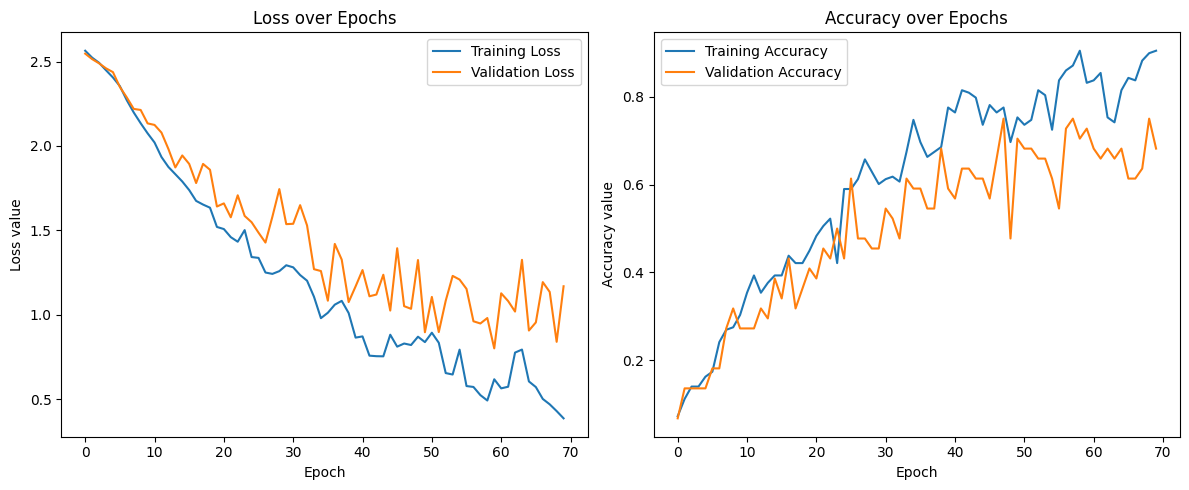

In [43]:
import matplotlib.pyplot as plt

# print(history.history.keys()) # View available metrics, e.g., ['loss', 'accuracy', 'val_loss', 'val_accuracy']

# 4. Plot training and validation loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.ylabel('Loss value')
plt.xlabel('Epoch')
plt.legend()

# 5. Plot training and validation accuracy (if applicable)
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.ylabel('Accuracy value')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
model.save("models/hand_gesture_modelv6.keras")
model.save("website/hand_gesture_modelv6.keras")

In [10]:
print(find_max_length(raw_test, raw_train, raw_val))

186
